<h1>Assignment 02: Feature Extraction with VGG16 (Model 2)</h1>

<h2>1. Business understanding</h2>

Our main goal is to create a model with our own image dataset and experiment with three different approaches for training the models and compare which of these approaches works the best.

1. <b>Custom Convolutional Neural Network (CNN)</b> built from scratch using our own dataset.
2. <b>Feature Extraction using a pre-trained VGG16 model</b>, training only a custom classifier on top of the extracted features.
3. <b>Fine-tuned pre-trained model</b> with frozen lower layers and adapted upper layers.

This notebook contains the approaches and experiments of the model number two. Report and comparisons are done in a separate notebook.



<h2>2. Data understanding</h2>

In [23]:
import os, shutil, pathlib
import matplotlib.pyplot as plt
import keras
from keras import layers
from keras.utils import image_dataset_from_directory

rps_dir = pathlib.Path("./rps") #directory with all data

In [24]:
import tensorflow as tf
print(tf.__version__)
print(tf.config.list_physical_devices())

2.21.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [25]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(180, 180, 3))
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 180, 180, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 180, 180, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 90, 90, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 90, 90, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 45, 45, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 45, 45, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 45, 45, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 45, 45, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 22, 22, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 22, 22, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 22, 22, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 22, 22, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 11, 11, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 11, 11, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 11, 11, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 11, 11, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 5, 5, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

<h2>3. Data preparation</h2>

Before training the model data preparation is done. The two main steps are loading the datasets into the notebook for training, evaluating and testing the model. Next really important step is to do <i>feature extraction</i>, our prepared data goes through VGG16 pre-trained model, the results are extracted and used to train our own model.

<h3>3.1 Load and Prepare Datasets</h3>

In [189]:
#SUPPORTS FORMATS: JPEG (.jpg, .jpeg), PNG (.png), BMP (.bmp) AND GIF (.gif)

train_dataset = image_dataset_from_directory(
    rps_dir / "train",
    image_size = (180, 180),
    batch_size = 32)

validation_dataset = image_dataset_from_directory(
    rps_dir / "validation",
    image_size = (180, 180),
    batch_size = 32)

test_dataset = image_dataset_from_directory(
    rps_dir / "test",
    image_size = (180, 180),
    batch_size = 32,
    shuffle=False)

Found 191 files belonging to 3 classes.
Found 53 files belonging to 3 classes.
Found 53 files belonging to 3 classes.


<h4>Folder Configuration and Loading Dataset</h4>

`train_dataset = image_dataset_from_directory(rps_dir / "train", image_size = (180, 180), batch_size = 32)`

`rps_dir / "train"` <br/>
- Makes a search in the directory.
- Keras makes assumption that there are subfolders for each class, which there are.
    - Rock
    - Paper
    - Scissors
- Keras recognizes each subfolder as its own separate class.

`image_size` <br/>
- Resizes each pictures to be automatically 180x180 pixels.
- <b>This is a really important step, because now each image has exactly the same size when feeded to model.</b>

`batch_size` <br/>
- Configures the amount of data is feeded to the model. In this models case, it is feeded in 32 batches. (This speeds the training)
  
<h4>Separate dataset in three</h4>

The same process is repeated on three different folders, `train_dataset`, `validation dataset` & `test_dataset`.

- `train_dataset`: Training data, approximately 80% of the images with which the model is trained.
- `validation_dataset`: Validation data, approximately 10% of the images, this is used for observing if the models start to overfit while being trained.
- `test_dataset`: Test data, approximately 10% of the images, this is used to test the final model. This images are only used when the model trained and overfitting with validation data is adjusted.

This is a great way to automatize importing images and classifying them.

<h3>3.2 Feature Extraction</h3>

It takes a lot of resources to compute the VGG16 convolutional features every time we train the model, so it is wise to run our images through VGG16 once and save the results in memory. This way, we can train our own model using the features extracted by VGG16, which makes the training process extremely fast.

In [190]:
import numpy as np

def get_features_and_labels(dataset):
    all_features = []
    all_labels = []
    for images, labels in dataset:
        preprocessed_images = keras.applications.vgg16.preprocess_input(images)
        features = conv_base.predict(preprocessed_images)
        all_features.append(features)
        all_labels.append(labels)
    return np.concatenate(all_features), np.concatenate(all_labels)

train_features, train_labels = get_features_and_labels(train_dataset)
val_features, val_labels = get_features_and_labels(validation_dataset)
test_features, test_labels = get_features_and_labels(test_dataset)

print('Train shape:',train_features.shape, '\nValidation shape', val_features.shape,'\nTest shape', test_features.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Train shape: (191, 5, 5, 512) 
Validation shape (53, 5, 5, 512) 
Test shape (53, 5, 5, 512)


<h4>What is the output?</h4>

The results show that our Rock-Paper-Scissors data is run throught the VGG16 model. It took approximately <b>2-3 seconds to run one batch through one convolutional layer</b>.

<b>Output</b> <br/>
`(AMOUNT_OF_IMAGES_IN_OUR_DATASET, NEW_WIDTH, NEW_LENGHT, DEPTH)`

After running our 191 training images through the VGG16 convolutional base, output is a shape (191, 5, 5, 512). Each feature map has a size of 5x5 and a depth of 512 channels. <b>The depth channel contains visual data like <i>vertical lines, curves, textures, and color patterns</i> extracted from the original images</b>.

---

<h4>Feature Extraction Function</h4>

`get_features_and_labels(dataset)` <br/>

- This function takes a dataset as a paremeter (e.g. <i>train_dataset</i>) and goes trought the images in batches.

`preprocess_input(images)` <br/>

- Adjusts image values and colors to the format that VGG16 is using.

`conv_base.predict(preprocessed_images)` <br/>

- This feeds images throung the VGG16 layers. These layers do not learn anything new, it works more like an filter that formats our images to a specific feature maps. In this case ( ... , 5, 5 512).

`np.concatenate(...)` <br/>

- This collects all the results together and assembles it as one NumPy -table with <i>all_features</i> and <i>all_labels</i>.

This function is used three times, ones on each of our datasets `train_dataset`, `validation_dataset` & `test_dataset`.

<h2>4. Modeling</h2>

The idea is to experiment and create three models with different optimizers and layer adjustments to find the most suitable approach. The biggest problem is that our own dataset is very small. Therefore, it will be a challenge to achieve good generalization and avoid overfitting altogether.

<h4>Training Model #1</h4>

In [191]:
#MODEL 01

model_01 = keras.Sequential([

#input
keras.Input(shape=(5, 5, 512)),

#hidden
layers.Flatten(),
layers.Dense(256),
layers.Dropout(0.5),

#output
layers.Dense(3, activation="softmax")
])

model_01.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="rmsprop",
    metrics=["accuracy"]
)

history_01 = model_01.fit(
    train_features, train_labels,
    epochs=100,
    validation_data=(val_features, val_labels))

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - accuracy: 0.4503 - loss: 71.0893 - val_accuracy: 0.5849 - val_loss: 21.8373
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8901 - loss: 6.6314 - val_accuracy: 0.6792 - val_loss: 17.6819
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9529 - loss: 1.0662 - val_accuracy: 0.6604 - val_loss: 18.8859
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.9738 - loss: 0.8096 - val_accuracy: 0.6415 - val_loss: 19.2301
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.9529 - loss: 1.5500 - val_accuracy: 0.5094 - val_loss: 46.3590
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9476 - loss: 2.7454 - val_accuracy: 0.6415 - val_loss: 19.3642
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9686 - loss: 1.3022 - val_accuracy: 0.6604 - val_loss: 27.1143
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.9791 - loss: 0.6024 - val_accuracy: 0.6792 - 

<h4>Results: Model #1</h4>

- Accuracy of 100%

---

<h4>Training Model #2</h4>

In [192]:
#MODEL 02

model_02 = keras.Sequential([
    keras.Input(shape=(5, 5, 512)),
    
    layers.GlobalAveragePooling2D(),
    
    layers.Dense(64, activation="relu", kernel_regularizer=keras.regularizers.l2(0.001)),
    layers.Dropout(0.4),
    
    layers.Dense(3, activation="softmax")
])

model_02.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    metrics=["accuracy"]
)

history_02 = model_02.fit(
    train_features, train_labels,
    epochs=150,
    validation_data=(val_features, val_labels))

Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step - accuracy: 0.3246 - loss: 3.3918 - val_accuracy: 0.2642 - val_loss: 3.7325
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4084 - loss: 2.6168 - val_accuracy: 0.2264 - val_loss: 3.2635
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.4084 - loss: 2.2693 - val_accuracy: 0.2453 - val_loss: 2.8985
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.4503 - loss: 2.0185 - val_accuracy: 0.3019 - val_loss: 2.6698
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.3874 - loss: 2.1441 - val_accuracy: 0.3208 - val_loss: 2.4818
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.4660 - loss: 1.8934 - val_accuracy: 0.3396 - val_loss: 2.3594
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.4921 - loss: 1.8834 - val_accuracy: 0.3585 - val_loss: 2.2796
Epoch 8/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.4974 - loss: 1.8530 - val_accuracy: 0.3585 - val_loss:

<h4>Results: Model #2</h4>

- Accuracy of 100%

---

<h4>Training Model #3</h4>

In [193]:
#MODEL 03

model_03 = keras.Sequential([
    keras.Input(shape=(5, 5, 512)),

    layers.GlobalAveragePooling2D(),
    
    layers.Dense(128, activation="relu", kernel_regularizer=keras.regularizers.l2(0.005)),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    
    layers.Dense(64, activation="relu", kernel_regularizer=keras.regularizers.l2(0.005)),
    layers.Dropout(0.3),
    
    layers.Dense(3, activation="softmax")
])

model_03.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    metrics=["accuracy"]
)

history_03 = model_03.fit(
    train_features, train_labels,
    epochs=500,
    validation_data=(val_features, val_labels))

Epoch 1/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 82ms/step - accuracy: 0.2932 - loss: 3.4339 - val_accuracy: 0.3208 - val_loss: 4.9843
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.3874 - loss: 3.0456 - val_accuracy: 0.2830 - val_loss: 4.6775
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.3613 - loss: 3.0491 - val_accuracy: 0.3019 - val_loss: 4.4191
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.3927 - loss: 2.9532 - val_accuracy: 0.2830 - val_loss: 4.2127
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.3979 - loss: 3.0388 - val_accuracy: 0.3019 - val_loss: 4.0327
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4188 - loss: 2.8966 - val_accuracy: 0.3208 - val_loss: 3.8868
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.3770 - loss: 2.9679 - val_accuracy: 0.3208 - val_loss: 3.7527
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4031 - loss: 2.8736 - val_accuracy: 0.3396 - val_loss:

<h4>Model #3</h4>

- Accuracy of 100%

<h3>4.1 Results</h3>

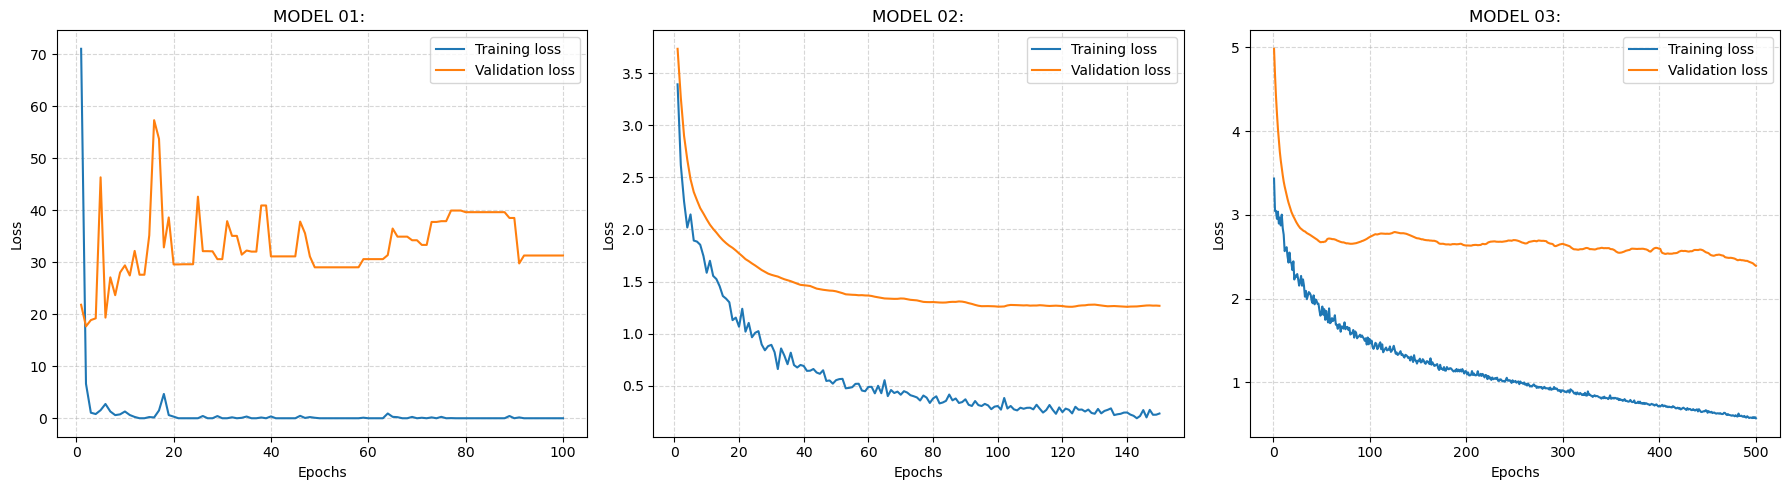

In [203]:
ig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# model 1
epochs_1 = list(range(1, len(history_01.history["loss"]) + 1))
ax1.plot(epochs_1, history_01.history["loss"], label="Training loss")
ax1.plot(epochs_1, history_01.history["val_loss"], label="Validation loss")
ax1.set_title("MODEL 01: ")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)


# model 2
epochs_2 = list(range(1, len(history_02.history["loss"]) + 1))
ax2.plot(epochs_2, history_02.history["loss"], label="Training loss")
ax2.plot(epochs_2, history_02.history["val_loss"], label="Validation loss")
ax2.set_title("MODEL 02:")
ax2.set_xlabel("Epochs")
ax2.set_ylabel("Loss")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

#model 3
epochs_3 = list(range(1, len(history_03.history["loss"]) + 1))
ax3.plot(epochs_3, history_03.history["loss"], label="Training loss")
ax3.plot(epochs_3, history_03.history["val_loss"], label="Validation loss")
ax3.set_title("MODEL 03:")
ax3.set_xlabel("Epochs")
ax3.set_ylabel("Loss")
ax3.legend()
ax3.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

<h2>5. Evaluation</h2>

In [206]:
accuracy = history_02.history["accuracy"]
val_accuracy = history_02.history["val_accuracy"]
loss = history_02.history["loss"]
val_loss = history_02.history["val_loss"]
epochs = list(range(1, len(accuracy)+1)) 

test_loss, test_acc = model_02.evaluate(test_features, test_labels)

print('Test accuracy: ', test_acc)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6226 - loss: 1.3880
Test accuracy:  0.6226415038108826


In [207]:
model_02.summary()

Model: "sequential_32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ global_average_pooling2d_8      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_84 (Dense)                │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_43 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_85 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,083 (387.05 KB)

 Trainable params: 33,027 (129.01 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 66,056 (258.04 KB)

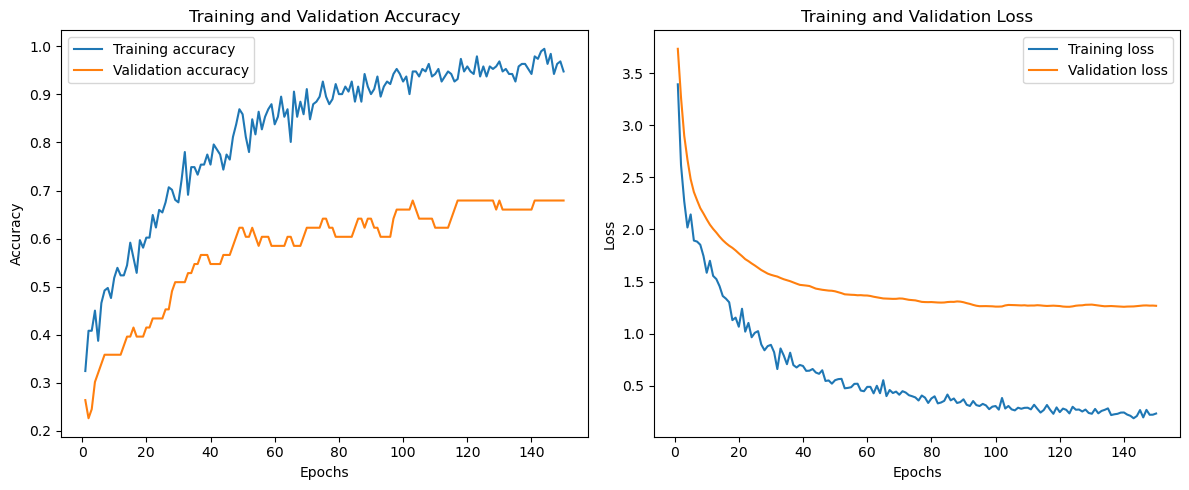

In [208]:
fig, (acc, loss_plt) = plt.subplots(1, 2, figsize=(12, 5))

# ACC PLOT
acc.plot(epochs, accuracy, label="Training accuracy")
acc.plot(epochs, val_accuracy, label="Validation accuracy")
acc.set_title("Training and Validation Accuracy")
acc.set_xlabel("Epochs")
acc.set_ylabel("Accuracy")
acc.legend()

# LOSS PLOT
loss_plt.plot(epochs, loss, label="Training loss")
loss_plt.plot(epochs, val_loss, label="Validation loss")
loss_plt.set_title("Training and Validation Loss")
loss_plt.set_xlabel("Epochs")
loss_plt.set_ylabel("Loss")
loss_plt.legend()

plt.tight_layout()
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


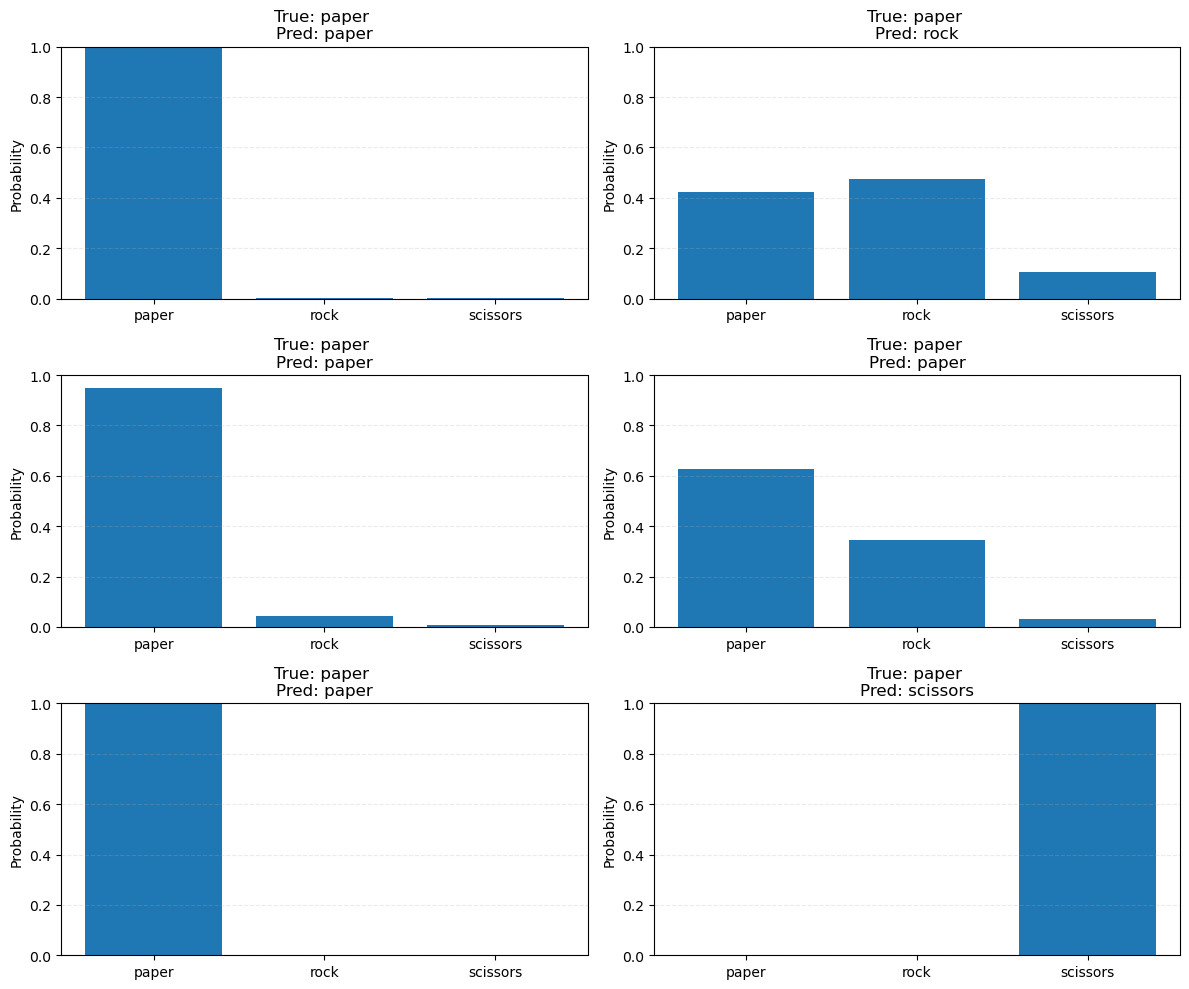

In [230]:
class_names = test_dataset.class_names
probs = model_03.predict(test_features)

fig, axes = plt.subplots(3, 2, figsize=(12, 10))
axes = axes.flatten()

for i in range(6):
    true_label = int(test_labels[i])
    pred_label = np.argmax(probs[i])
    
    ax = axes[i]
    ax.bar(class_names, probs[i])
    ax.set_title(f"True: {class_names[true_label]} \nPred: {class_names[pred_label]}")
    ax.set_ylabel("Probability")
    ax.set_ylim(0, 1)
    ax.grid(axis='y', linestyle='--', alpha=0.25)

plt.tight_layout()
plt.show()

<h2>6. Deployment</h2>

- Malli viedään käytäntöön (deployment).
- Tähän sisältyy tulosten viestiminen ja suositusten luominen siitä, miten mallia tulisi hyödyntää käytännössä tai mitä jatkotoimenpiteitä tulisi tehdä.